# 01 · Patient split and data audit

**Question.** Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage?

**What this notebook adds.** The template splits the official training images into training and validation *by image*. Here I check who the patients behind the images are, and split *by patient* instead, so no patient appears in two splits. The official test set is kept exactly as published.

**Hypothesis.** The image-level split leaks patients; a patient-level split removes all overlap while keeping the official 624-image test set unchanged.

**Feeds report sections 2 (data) and 5 (limitations).**

## Setup
Find the data (download it if missing), set the output folders, print versions.

In [1]:
import csv, re, sys, zipfile, platform, shutil
import requests
from collections import Counter
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from PIL import Image

# works locally or on Colab: ROOT/DATA_DIR point at the repo or /content
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content") if IN_COLAB else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
DATA_DIR = Path("/content/chest_xray") if IN_COLAB else ROOT / "data/chest_xray"
ZIP = Path("/content/ChestXRay2017.zip") if IN_COLAB else ROOT / "data/ChestXRay2017.zip"
URL = "https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded"
# fetch and unzip the Kermany chest X-ray data only if it is missing
if not (DATA_DIR / "train").exists():
    ZIP.parent.mkdir(parents=True, exist_ok=True)
    if not ZIP.exists():
        print("downloading", URL)
        with requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, stream=True, timeout=60) as resp:
            resp.raise_for_status()
            with open(ZIP, "wb") as f:
                shutil.copyfileobj(resp.raw, f, 1 << 20)
    print("unzipping", ZIP)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(ZIP.parent)
# my own outputs go to results/own; the new split is written to splits/
OUT = ROOT / "results/own"; OUT.mkdir(parents=True, exist_ok=True)
SPLITS = ROOT / "splits"; SPLITS.mkdir(exist_ok=True)
SEED = 0

# log library versions for the reproducibility section
import sklearn
print("python", platform.python_version(), "| torch", torch.__version__.split("+")[0],
      "| numpy", np.__version__, "| sklearn", sklearn.__version__)
print("ROOT =", ROOT, " DATA_DIR =", DATA_DIR)

python 3.11.11 | torch 2.14.1 | numpy 2.4.6 | sklearn 1.6.1
ROOT = /Users/ashok/Documents/ABROAD-NEW-INTAKE/SRH-MUNICH/WiSe-2026/biomedical-image/project/bia-pediatric-pneumonia-cxr  DATA_DIR = /Users/ashok/Documents/ABROAD-NEW-INTAKE/SRH-MUNICH/WiSe-2026/biomedical-image/project/bia-pediatric-pneumonia-cxr/data/chest_xray


## a · List every image
First I need the table of all images: which file, which class (from its folder), which official split. This also checks the published counts (5,232 training / 624 test).

In [2]:
# class names come straight from the folder names (NORMAL, PNEUMONIA)
CLASSES = sorted(d.name for d in (DATA_DIR / "train").iterdir() if d.is_dir())
print("classes:", CLASSES)
extra = [p.name for p in DATA_DIR.iterdir() if p.name not in ("train", "test")]
if extra: print("other entries in chest_xray (not used):", extra)

# one row per image: file, numeric label, official split
rows = []
for official in ("train", "test"):
    for k, c in enumerate(CLASSES):
        d = DATA_DIR / official / c
        if not d.exists(): continue
        for f in sorted(d.iterdir()):
            if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                rows.append({"file": f"{official}/{c}/{f.name}", "label": k, "official_split": official})

for official in ("train", "test"):
    for k, c in enumerate(CLASSES):
        # printed counts double-check the published numbers (5 232 train / 624 test)
        n = sum(1 for r in rows if r["official_split"] == official and r["label"] == k)
        print(f"{official:5s} {c:10s} {n}")
print("total:", len(rows))

classes: ['NORMAL', 'PNEUMONIA']
other entries in chest_xray (not used): ['.DS_Store']
train NORMAL     1349
train PNEUMONIA  3883
test  NORMAL     234
test  PNEUMONIA  390
total: 5856


## b · Who is the patient?
The file names carry a patient hint: `person12_bacteria_45` is person 12, `IM-0115-0001` is patient IM-0115. I use the template's rule exactly, count how each name type is used, and check that no patient carries both labels.

patient ID per name type: {'IM': 666, 'NORMAL2-IM': 917, 'person': 4273}
fallback (no rule matched): 0 []
3118 patients; images per patient: min 1, median 1, max 31
patients carrying BOTH labels: 0 []


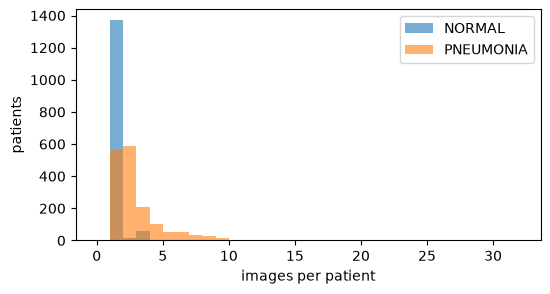

In [3]:
# patient-ID rule taken verbatim from the template: file names encode the child
def PATIENT_ID(name):
    stem = name.rsplit(".", 1)[0]
    if stem.startswith("person"):
        return stem.split("_")[0]
    m = re.match(r"(NORMAL2-)?IM-(\d+)-\d+", stem)
    return (m.group(1) or "") + "IM-" + m.group(2) if m else stem

def id_kind(stem):
    if stem.startswith("person"): return "person"
    m = re.match(r"(NORMAL2-)?IM-(\d+)-\d+", stem)
    if m: return "NORMAL2-IM" if m.group(1) else "IM"
    return "fallback"

for r in rows:
    stem = Path(r["file"]).name.rsplit(".", 1)[0]
    # attach the patient ID and its type to every image row
    r["patient"] = PATIENT_ID(Path(r["file"]).name)
    r["id_type"] = id_kind(stem)

print("patient ID per name type:", dict(Counter(r["id_type"] for r in rows)))
# fallback = names no rule matched; must be 0 or the ID rule is wrong
fb = [r["file"] for r in rows if r["id_type"] == "fallback"]
print("fallback (no rule matched):", len(fb), fb[:5])

# how many images each child contributes
per_patient = Counter(r["patient"] for r in rows)
ipp = np.array(list(per_patient.values()))
print(f"{len(per_patient)} patients; images per patient: min {ipp.min()}, median {np.median(ipp):.0f}, max {ipp.max()}")

# a child carrying both labels would break a label-clean patient split
pat_labels = {}
for r in rows: pat_labels.setdefault(r["patient"], set()).add(r["label"])
both_labels = sorted(p for p, s in pat_labels.items() if len(s) > 1)
print("patients carrying BOTH labels:", len(both_labels), both_labels[:10])

pat_label0 = {}
for r in rows: pat_label0.setdefault(r["patient"], r["label"])
# histogram: images per child, per class
fig, ax = plt.subplots(figsize=(6, 3))
for k, c in enumerate(CLASSES):
    vals = [per_patient[p] for p in per_patient if pat_label0[p] == k]
    ax.hist(vals, bins=range(0, ipp.max() + 2), alpha=0.6, label=c)
ax.set_xlabel("images per patient"); ax.set_ylabel("patients"); ax.legend()
fig.savefig(OUT / "01_patients_per_id.png", dpi=150, bbox_inches="tight"); plt.show()

## c · Reproduce the template's leakage
The template reported patients that are in the official training *and* the official test set. I reproduce that number, then break it down: which name types, which labels — and how many training images belong to those patients. I also rebuild the template's random 10 % validation split (same seed, same order) to compare overlaps later.

In [4]:
# which children sit in official train vs official test
pat_of = {s: {r["patient"] for r in rows if r["official_split"] == s} for s in ("train", "test")}
both_pat = pat_of["train"] & pat_of["test"]
print(f"patients in official train AND official test: {len(both_pat)}")

pat_type = {r["patient"]: r["id_type"] for r in rows}
print("  by ID type:", dict(Counter(pat_type[p] for p in both_pat)))
lab_count = Counter()
for p in both_pat:
    labs = pat_labels[p]
    lab_count[" + ".join(sorted(CLASSES[l] for l in labs))] += 1
print("  by label(s) on that patient:", dict(lab_count))

# how many official-train images belong to the leaked children
n_leak_imgs = sum(1 for r in rows if r["official_split"] == "train" and r["patient"] in both_pat)
print("official-train images belonging to those patients:", n_leak_imgs)

# the template's split: files ordered by class then name (as load_folder), rng(0), first 10 % -> val
train_rows = [r for r in rows if r["official_split"] == "train"]   # already class-major, name-sorted
o = np.random.default_rng(0).permutation(len(train_rows))
tmpl_val_idx = set(o[: len(o) // 10].tolist())
for i, r in enumerate(train_rows):
    r["tmpl_split"] = "val" if i in tmpl_val_idx else "train"
for r in rows:
    if r["official_split"] == "test": r["tmpl_split"] = "test"

# shared children per split pair - all three must be 0 for a clean split
def pset(split_key, s):
    return {r["patient"] for r in rows if r[split_key] == s}
print("template split: train/test", len(pset("tmpl_split", "train") & pset("tmpl_split", "test")),
      "| train/val", len(pset("tmpl_split", "train") & pset("tmpl_split", "val")),
      "| val/test", len(pset("tmpl_split", "val") & pset("tmpl_split", "test")))

patients in official train AND official test: 170
  by ID type: {'person': 170}
  by label(s) on that patient: {'PNEUMONIA': 170}
official-train images belonging to those patients: 457
template split: train/test 161 | train/val 297 | val/test 32


## d · New split by patient
Test stays exactly the official 624 images. Official-train images whose patient also shows up in test are **dropped** — better safe than leaked. The remaining patients are split per class: sorted patient IDs, shuffled with seed 0, the first 15 % go to validation. Then every image gets its split in `splits/patient_split.csv`.

In [5]:
# drop official-train images of children who are also in test, so no child sits in two splits
test_pat = pat_of["test"]
for r in rows:
    if r["official_split"] == "test": r["split"] = "test"
    elif r["patient"] in test_pat:  r["split"] = "dropped"

# each remaining child gets one label: the majority over its images
plab = {}
for r in rows:
    if r["official_split"] == "train" and r["patient"] not in test_pat:
        plab.setdefault(r["patient"], Counter())[r["label"]] += 1
majority = {p: c.most_common(1)[0][0] for p, c in plab.items()}   # ties -> the label seen first

# per class: sorted children, seeded shuffle, first 15 % go to validation
rng = np.random.default_rng(SEED); val_pat = set()
for k in range(len(CLASSES)):
    ids = sorted(p for p in plab if majority[p] == k)
    ids = list(np.array(ids)[rng.permutation(len(ids))])
    val_pat |= set(ids[: round(0.15 * len(ids))])
    print(f"{CLASSES[k]:10s} patients {len(ids)}, to val {round(0.15 * len(ids))}")

for r in rows:
    # every image inherits its child's split
    r.setdefault("split", "val" if r["patient"] in val_pat else "train")

# write splits/patient_split.csv - the file every later notebook reads
rows.sort(key=lambda r: r["file"])
with open(SPLITS / "patient_split.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["file", "label", "patient", "official_split", "split"])
    for r in rows: w.writerow([r["file"], r["label"], r["patient"], r["official_split"], r["split"]])
print("wrote", SPLITS / "patient_split.csv", "|", dict(Counter(r["split"] for r in rows)))

NORMAL     patients 1219, to val 183
PNEUMONIA  patients 1472, to val 221


wrote /Users/ashok/Documents/ABROAD-NEW-INTAKE/SRH-MUNICH/WiSe-2026/biomedical-image/project/bia-pediatric-pneumonia-cxr/splits/patient_split.csv | {'test': 624, 'train': 4043, 'val': 732, 'dropped': 457}


## e · Check the split before trusting it
Asserts, not eyeballs: no patient in two of train/val/test, every file exactly once, test unchanged.

In [6]:
# assert, don't eyeball: no child in two splits, no file twice, test unchanged at 624
sp = {s: {r["patient"] for r in rows if r["split"] == s} for s in ("train", "val", "test")}
assert not (sp["train"] & sp["val"]) and not (sp["train"] & sp["test"]) and not (sp["val"] & sp["test"]), "patient overlap!"
assert len({r["file"] for r in rows}) == len(rows), "duplicate file"
assert {r["file"] for r in rows if r["split"] == "test"} == {r["file"] for r in rows if r["official_split"] == "test"}
assert len([r for r in rows if r["split"] == "test"]) == 624
assert sum(Counter(r["split"] for r in rows).values()) == len(rows)
print("all checks passed: 0 shared patients,", len(rows), "files, test = 624 official images")

all checks passed: 0 shared patients, 5856 files, test = 624 official images


## f · Near-twins across the new splits
Different patients can still produce near-identical images. Same check as the template: images to 64 x 64 grey-style RGB, scaled 0-1, nearest neighbour by Euclidean distance / sqrt(dim); a pair closer than 0.03 is a "twin". I check test-vs-train and val-vs-train — and the template's split for comparison.

In [7]:
# shrink every image to 64x64 grey-style so distances are cheap
def small(files, batch=256):
    out = []
    for i in range(0, len(files), batch):
        x = np.stack([np.asarray(Image.open(DATA_DIR / f).convert("RGB").resize((128, 128), Image.BILINEAR))
                      for f in files[i:i + batch]])
        t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
        out.append(F.interpolate(t, size=(64, 64), mode="bilinear", antialias=True).reshape(len(t), -1))
    return torch.cat(out)

# embed all images once, then map file -> row index
emb = small([r["file"] for r in rows])
pos = {r["file"]: i for i, r in enumerate(rows)}
def idx(split_key, s): return np.array([i for i, r in enumerate(rows) if r[split_key] == s])

# a 'twin' = nearest neighbour closer than 0.03 (the template's rule)
def twin_count(q, ref):
    A, B = emb[q], emb[ref]
    d, nn = torch.cat([torch.cdist(A[i:i + 500], B) for i in range(0, len(A), 500)]).div(B.shape[1] ** 0.5).min(1)
    return (d < 0.03).nonzero().ravel(), d, nn

# count twins for the new split and the template's split side by side
tw = {}
for name, key, qs, rs in [("new test-vs-train", "split", "test", "train"), ("new val-vs-train", "split", "val", "train"),
                          ("tmpl test-vs-train", "tmpl_split", "test", "train"), ("tmpl val-vs-train", "tmpl_split", "val", "train")]:
    hits, d, nn = twin_count(idx(key, qs), idx(key, rs))
    tw[name] = (hits, d, nn, idx(key, qs), idx(key, rs))
    print(f"{name:20s}: {len(hits)} twins (< 0.03)")

# show a few twin pairs by eye
pairs = [(name, i) for name, (hits, d, nn, q, r) in tw.items() if name.startswith("new") for i in hits[:6]]
if pairs:
    fig, axes = plt.subplots(2, len(pairs[:6]), figsize=(2 * len(pairs[:6]), 4.4), squeeze=False)
    for k, (name, i) in enumerate(pairs[:6]):
        hits, d, nn, q, r = tw[name]
        for row, j, t in [(0, q[i], name.split()[1].split("-")[0]), (1, r[nn[i]], "train")]:
            axes[row, k].imshow(np.asarray(Image.open(DATA_DIR / rows[j]["file"]).convert("RGB").resize((128, 128), Image.BILINEAR)))
            axes[row, k].set_title(f"{t}\nd={d[i]:.3f}", fontsize=8); axes[row, k].axis("off")
    fig.savefig(OUT / "01_twins.png", dpi=150, bbox_inches="tight"); plt.show()
    for name, i in pairs[:6]:
        hits, d, nn, q, r = tw[name]
        print(name, "|", rows[q[i]]["file"], "(", rows[q[i]]["patient"], ") <->",
              rows[r[nn[i]]]["file"], "(", rows[r[nn[i]]]["patient"], ")")
else:
    print("no near-twins in the new split")

new test-vs-train   : 0 twins (< 0.03)
new val-vs-train    : 0 twins (< 0.03)


tmpl test-vs-train  : 0 twins (< 0.03)
tmpl val-vs-train   : 3 twins (< 0.03)
no near-twins in the new split


## g · Save the numbers
Counts per split (images and patients) for the report, and the side-by-side overlap table: template split vs patient-level split.

In [8]:
# counts per split (images and children) for the report
with open(OUT / "01_counts.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["split", "normal_images", "pneumonia_images", "total_images",
                "normal_patients", "pneumonia_patients", "total_patients", "pneumonia_share"])
    counts_table = []
    for s in ("train", "val", "test", "dropped"):
        rs = [r for r in rows if r["split"] == s]
        ni = sum(1 for r in rs if r["label"] == 0); pi = len(rs) - ni
        npp = len({r["patient"] for r in rs if r["label"] == 0}); ppp = len({r["patient"] for r in rs if r["label"] == 1})
        tp = len({r["patient"] for r in rs})
        share = pi / len(rs) if rs else 0
        w.writerow([s, ni, pi, len(rs), npp, ppp, tp, f"{share:.3f}"])
        counts_table.append([s, ni, pi, len(rs), npp, ppp, tp, share])
        print(f"{s:8s} normal {ni:5d} pneumonia {pi:5d} | patients {tp:4d} | pneumonia share {share:.1%}")

# side-by-side overlap: template image-level split vs my patient-level split
tmpl_ov = [len(pset("tmpl_split", "train") & pset("tmpl_split", "test")),
           len(pset("tmpl_split", "train") & pset("tmpl_split", "val")),
           len(pset("tmpl_split", "val") & pset("tmpl_split", "test"))]
new_ov = [len(sp["train"] & sp["test"]), len(sp["train"] & sp["val"]), len(sp["val"] & sp["test"])]
by_type = Counter(pat_type[p] for p in both_pat)

# save the overlap table as markdown for the report
overlap_md = f"""# 01 · patient overlap: template split vs patient-level split

| overlap / twins | template split (image-level) | new split (patient-level) |
|---|---|---|
| patients train &cap; test | {tmpl_ov[0]} | {new_ov[0]} |
| patients train &cap; val | {tmpl_ov[1]} | {new_ov[1]} |
| patients val &cap; test | {tmpl_ov[2]} | {new_ov[2]} |
| near-twins test vs train | {len(tw['tmpl test-vs-train'][0])} | {len(tw['new test-vs-train'][0])} |
| near-twins val vs train | {len(tw['tmpl val-vs-train'][0])} | {len(tw['new val-vs-train'][0])} |

**The {len(both_pat)} patients in official train &cap; official test, by ID type:** """ + \
    ", ".join(f"{k}: {v}" for k, v in sorted(by_type.items())) + f""". By label(s): """ + \
    ", ".join(f"{k}: {v}" for k, v in sorted(lab_count.items())) + f""".

**Images dropped from training** because their patient also appears in the official test set: **{n_leak_imgs}** of {len(train_rows)}.
"""
(OUT / "01_overlap.md").write_text(overlap_md)
print(overlap_md)

train    normal  1152 pneumonia  2891 | patients 2287 | pneumonia share 71.5%
val      normal   197 pneumonia   535 | patients  404 | pneumonia share 73.1%
test     normal   234 pneumonia   390 | patients  427 | pneumonia share 62.5%
dropped  normal     0 pneumonia   457 | patients  170 | pneumonia share 100.0%
# 01 · patient overlap: template split vs patient-level split

| overlap / twins | template split (image-level) | new split (patient-level) |
|---|---|---|
| patients train &cap; test | 161 | 0 |
| patients train &cap; val | 297 | 0 |
| patients val &cap; test | 32 | 0 |
| near-twins test vs train | 0 | 0 |
| near-twins val vs train | 3 | 0 |

**The 170 patients in official train &cap; official test, by ID type:** person: 170. By label(s): PNEUMONIA: 170.

**Images dropped from training** because their patient also appears in the official test set: **457** of 5232.



## h · Twenty images, looked at by eye
Ten NORMAL and ten PNEUMONIA images from the new training split (random, seed 0), with label and patient ID. What to look for: "R" markers, corner text, tubes or electrodes — things that could give the label away.

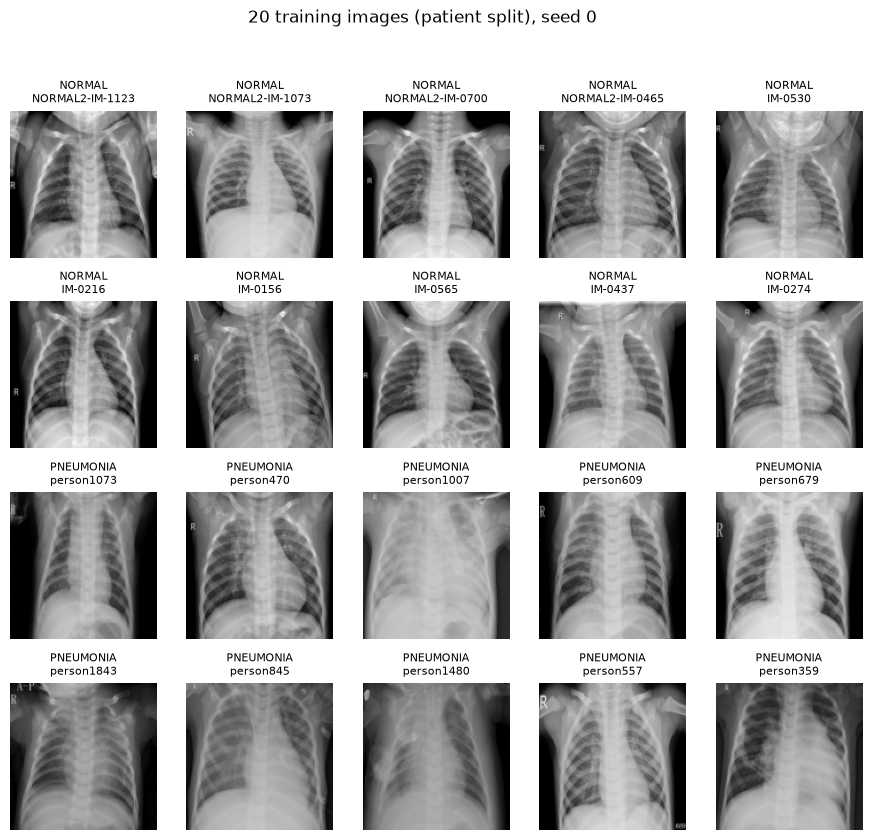

In [9]:
# look at 10 random NORMAL + 10 PNEUMONIA training images by eye
rng_ex = np.random.default_rng(SEED)
pick = []
for k in range(len(CLASSES)):
    cand = [r for r in rows if r["split"] == "train" and r["label"] == k]
    pick += [cand[i] for i in rng_ex.choice(len(cand), 10, replace=False)]

fig, axes = plt.subplots(4, 5, figsize=(11, 9.5))
for ax, r in zip(axes.ravel(), pick):
    ax.imshow(np.asarray(Image.open(DATA_DIR / r["file"]).convert("RGB").resize((128, 128), Image.BILINEAR)))
    ax.set_title(f"{CLASSES[r['label']]}\n{r['patient']}", fontsize=8); ax.axis("off")
fig.suptitle("20 training images (patient split), seed 0")
fig.savefig(OUT / "01_examples.png", dpi=150, bbox_inches="tight"); plt.show()

## i · Data table for the report
The template's A5 table, rebuilt for the patient split. Every number comes from the cells above; the text facts (licence, graders) were checked on the Mendeley page and in Kermany et al. (2018).

In [10]:
# rebuild the template's data table with the patient-split numbers
C = {row[0]: row for row in counts_table}       # split -> [s, normal, pneu, total, n_pat_norm, n_pat_pneu, n_pat, share]
n_tw = {k: len(v[0]) for k, v in tw.items()}
data_md = f"""# 01 · data table (patient-level split)

| | |
|---|---|
| Question | Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage? |
| Source, licence | Kermany, Zhang, Goldbaum (2018), "Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification", Mendeley Data V2, doi:10.17632/rscbjbr9sj.2 (chest X-ray part, `ChestXRay2017.zip`) · CC BY 4.0 (checked on the data set page) |
| Modality, size | X-ray (chest radiograph, anterior-posterior), 2D, JPEG, pixel size not reported; {len(rows)} images, used at 128 × 128 (baselines, frozen CNN) and 224 × 224 (fine-tuned CNN) |
| Labels | 2 classes: NORMAL, PNEUMONIA. Graded by two expert physicians after a quality check removed unreadable scans; a third expert checked the evaluation set (Kermany et al., 2018). Diagnosis read from the X-ray, not confirmed by a lab test |
| Classes | pneumonia share: training {C['train'][7]:.1%}, validation {C['val'][7]:.1%}, test {C['test'][7]:.1%}; floor (always pneumonia) on test {C['test'][2] / C['test'][3]:.1%} |
| Splits | by child: {C['train'][3]} / {C['val'][3]} / {C['test'][3]} images (training / validation / test) from {C['train'][6]} / {C['val'][6]} / {C['test'][6]} children; test = the official test folder, unchanged; {n_leak_imgs} training images of {len(both_pat)} children who are also in the test set were dropped |
| Quality checks | shared children before (template, split by image) → after (split by child): train∩test {tmpl_ov[0]} → {new_ov[0]}, train∩val {tmpl_ov[1]} → {new_ov[1]}, val∩test {tmpl_ov[2]} → {new_ov[2]}; near-twins val vs train {n_tw['tmpl val-vs-train']} → {n_tw['new val-vs-train']}, test vs train {n_tw['tmpl test-vs-train']} → {n_tw['new test-vs-train']}. {tmpl_ov[0]} = children in the template's training part and in test; {len(both_pat)} = all children of the official training folder who are in test (template training plus validation) |
| Where my data could differ | site: one hospital (Guangzhou Women and Children's Medical Center) · device and protocol: not reported · population: children aged 1–5 · labels: physicians reading the X-ray |
| A possible shortcut | "R" markers, corner text, tubes/electrodes (see `01_examples.png`); file names follow a different pattern per class (all {len(both_pat)} leaked children are `person*` pneumonia IDs). Tested in notebook 04 by masking the image border (`04_masking.md`) |
"""
(OUT / "01_data_table.md").write_text(data_md); print(data_md)

# 01 · data table (patient-level split)

| | |
|---|---|
| Question | Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage? |
| Source, licence | Kermany, Zhang, Goldbaum (2018), "Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification", Mendeley Data V2, doi:10.17632/rscbjbr9sj.2 (chest X-ray part, `ChestXRay2017.zip`) · CC BY 4.0 (checked on the data set page) |
| Modality, size | X-ray (chest radiograph, anterior-posterior), 2D, JPEG, pixel size not reported; 5856 images, used at 128 × 128 (baselines, frozen CNN) and 224 × 224 (fine-tuned CNN) |
| Labels | 2 classes: NORMAL, PNEUMONIA. Graded by two expert physicians after a quality check removed unreadable scans; a third expert checked the evaluation set (Kermany et al., 2018). Diagnosis read from the X-ray, not confirmed by a lab test |
| Classes | pneumonia share: training 71.5%, validation 73.1%, test 62.5%; floor (always pneumonia) on tes

## What I learned

- The official split is not patient-clean: 170 patients appear in both official train and official test — all of them `person*` pneumonia cases. The template's random image-level validation was worse: 297 patients shared with training, 32 even shared with test, plus 3 near-identical image pairs between validation and training.
- I dropped 457 training images (every one pneumonia) whose patient is in the test set, then split the rest by patient: 4,043 train / 732 val / 624 test images, 2,287 / 404 / 427 patients, zero shared patients and zero near-twins across splits.
- One side effect to remember: because only pneumonia patients leaked, dropping them changed the class balance a little — pneumonia is 71.5 % of my training images and 62.5 % of test.
- Why 170 and not the 161 from my first report: 161 counted only the children in the template's *training part* who are also in test; 170 counts every child of the official training folder (template training plus validation) who is also in test. Dropping all 170 is what keeps both training and validation clean.

Next: `02_baselines.ipynb` uses `splits/patient_split.csv`.